# Notebook 02: Giai đoạn 1 — Khử ám hồng bảo toàn texture, AWB có kiểm soát, khử nhiễu thích nghi
1. **Khử hồng chỉ dịch chroma** — $e=\max(0,\tfrac{R+B}{2}-G)$, $\delta=k\,\alpha\,e$:
   $R'=R-\delta,\; B'=B-\delta,\; G'=G+0.704\,\delta$ (0.704 giữ nguyên $Y_{601}$ ⇒ không làm phẳng texture). Mặt nạ $\alpha$ được *dilate 7×7 + Gauss σ=2* để phủ vùng biên; vùng R/B bão hoà được tiêm high-pass của kênh G.
2. **AWB Shades-of-Gray ($p=6$)** loại highlight bão hoà, vùng cây xanh, pixel bão hoà màu, pixel tối; gain ∈ [0.75, 1.25] với vùng chết 5 %, chuẩn hoá giữ độ sáng.
3. **Khử nhiễu thích nghi**: $\hat\sigma=\mathrm{median}(|HH_1|)/0.6745$; $h_{NLM}=0.85\hat\sigma$; mặt nạ cấu trúc từ gradient chuẩn hoá theo $\hat\sigma$; chroma lọc bằng Guided Filter dẫn bởi luminance.

PCI trước: 32.53%
PCI sau Giai đoạn 1: 0.00%
sigma ước lượng: 1.48


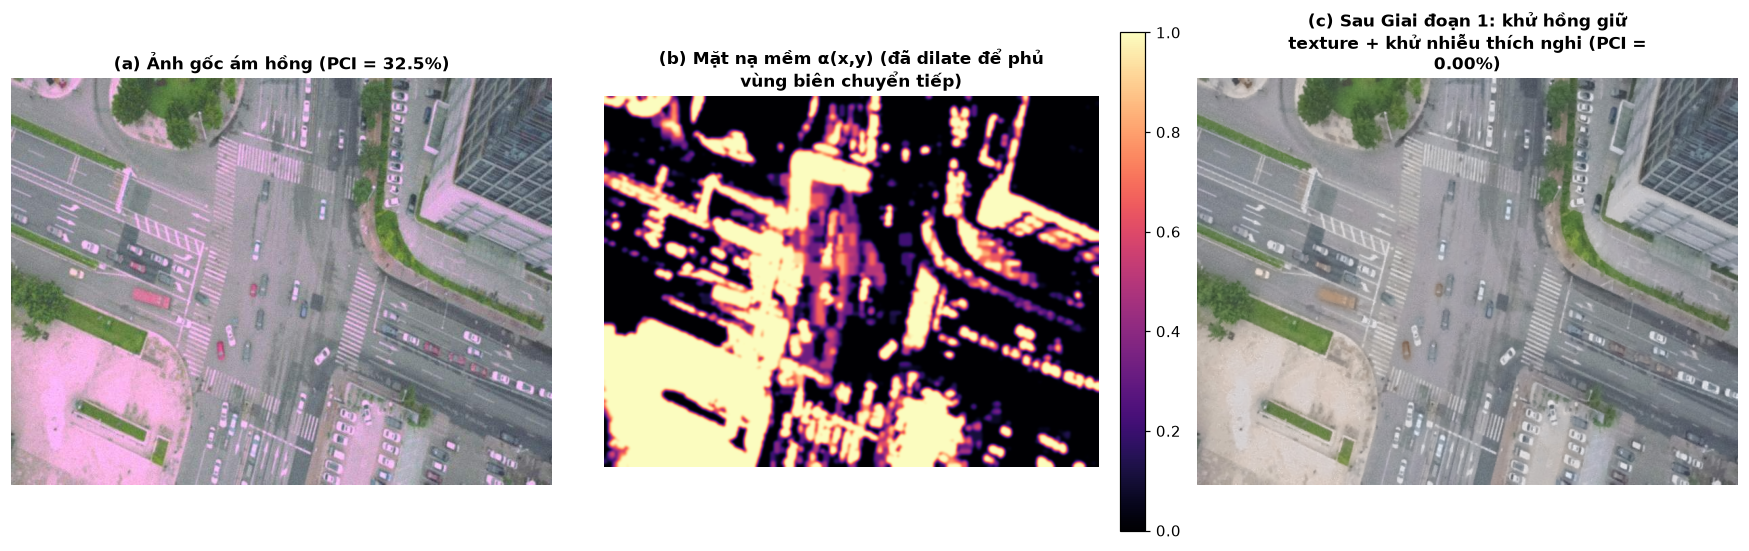

In [1]:
import os, sys, cv2, pandas as pd
ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))  # notebook đặt trong notebooks/
sys.path.insert(0, ROOT)
from src.uav_pipeline import run_stage1_preprocess, compute_pink_cast_index, estimate_noise_sigma
img = cv2.imread(f"{ROOT}/data/samples/sample_real_sky_pink.jpg")
s1, alpha = run_stage1_preprocess(img)
print(compute_pink_cast_index(img), compute_pink_cast_index(s1), estimate_noise_sigma(img))

### Ca ám hồng nặng (001, 013, 032): TRƯỚC vs SAU, kèm zoom texture

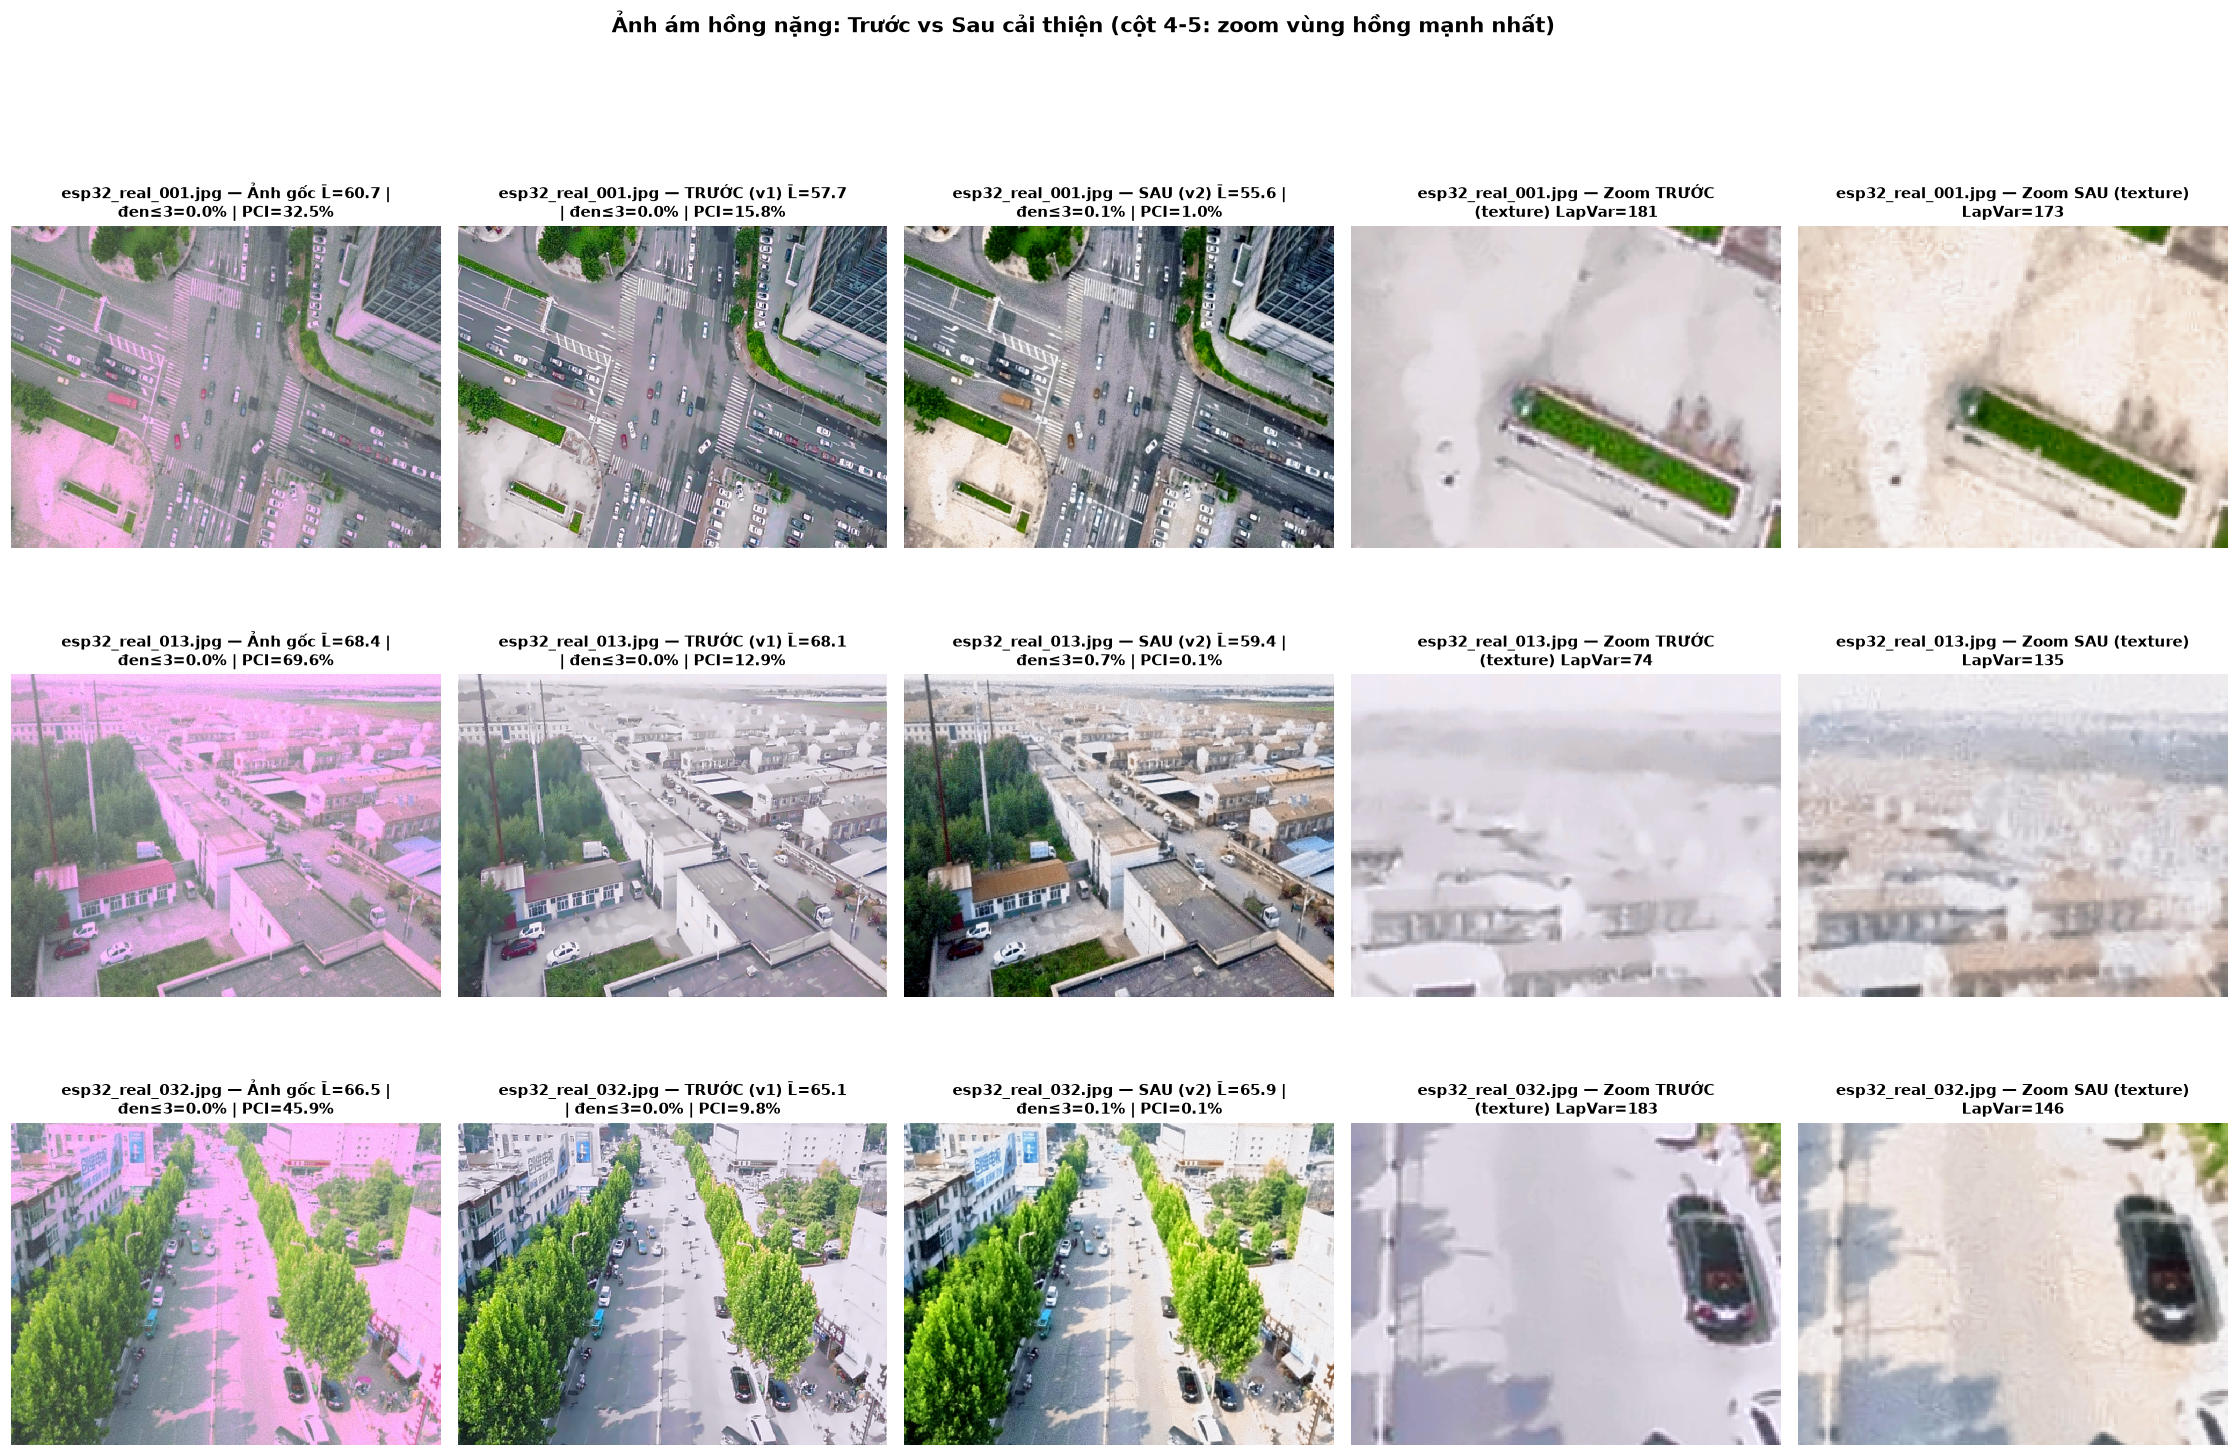

In [2]:
# results/figures/fig6_pink_before_after.png